In [1]:
lugares = {
    "Colegio Guadalupe (San Sebastián, Cusco)": (-13.5300, -71.9190),
    "UNSAAC (Cusco)": (-13.5254, -71.9568),
    "Plaza de Urubamba": (-13.3050, -72.1166),
    "Instituto de Salvación (Madre de Dios)": (-12.8361, -71.3611),
}

for nombre, (lat, lon) in lugares.items():
    print(f"{nombre}: lat={lat}, lon={lon}")

Colegio Guadalupe (San Sebastián, Cusco): lat=-13.53, lon=-71.919
UNSAAC (Cusco): lat=-13.5254, lon=-71.9568
Plaza de Urubamba: lat=-13.305, lon=-72.1166
Instituto de Salvación (Madre de Dios): lat=-12.8361, lon=-71.3611


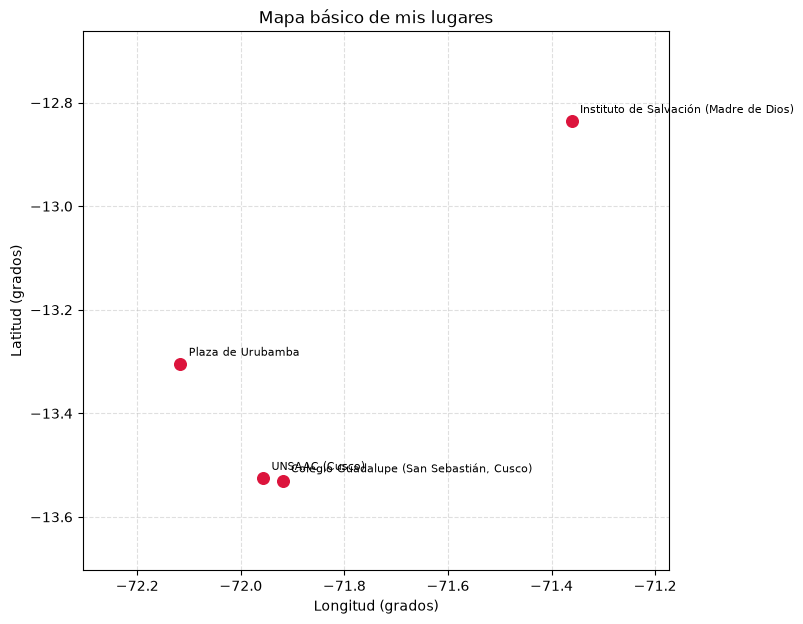

In [2]:
import matplotlib.pyplot as plt

lats = [coord[0] for coord in lugares.values()]
lons = [coord[1] for coord in lugares.values()]
nombres = list(lugares.keys())

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(lons, lats, color="crimson", s=70, zorder=3)
for nombre, lat, lon in zip(nombres, lats, lons):
    ax.annotate(nombre, (lon, lat), textcoords="offset points", xytext=(6, 6), fontsize=8)

ax.set_xlabel("Longitud (grados)")
ax.set_ylabel("Latitud (grados)")
ax.set_title("Mapa básico de mis lugares")
ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.4)
ax.margins(0.25)
plt.savefig("mapa_basico.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
import math

def distancia_haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # radio medio de la Tierra en km
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))
   

In [9]:
primero = nombres[0]
lat0, lon0 = lugares[primero]
print(f"Desde: {primero}")
for nombre in nombres[1:]:
    lat, lon = lugares[nombre]
    d = distancia_haversine(lat0, lon0, lat, lon)
    print(f"  -> {nombre}: {d:.2f} km")

Desde: Colegio Guadalupe (San Sebastián, Cusco)
  -> UNSAAC (Cusco): 4.12 km
  -> Plaza de Urubamba: 32.90 km
  -> Instituto de Salvación (Madre de Dios): 97.99 km


In [10]:
from itertools import combinations

pares = []
for a, b in combinations(nombres, 2):
    d = distancia_haversine(*lugares[a], *lugares[b])
    pares.append((d, a, b))

cercano = min(pares)
lejano = max(pares)
print(f"Par MÁS CERCANO: {cercano[1]} <-> {cercano[2]} = {cercano[0]:.2f} km")
print(f"Par MÁS LEJANO:  {lejano[1]} <-> {lejano[2]} = {lejano[0]:.2f} km")


Par MÁS CERCANO: Colegio Guadalupe (San Sebastián, Cusco) <-> UNSAAC (Cusco) = 4.12 km
Par MÁS LEJANO:  UNSAAC (Cusco) <-> Instituto de Salvación (Madre de Dios) = 100.17 km


In [12]:
import json

features = []
for nombre, (lat, lon) in lugares.items():
    features.append({
        "type": "Feature",
        "properties": {"nombre": nombre},
        "geometry": {"type": "Point", "coordinates": [lon, lat]}  # ¡[longitud, latitud]!
    })

geojson_mio = {"type": "FeatureCollection", "features": features}

with open("mis_lugares.geojson", "w", encoding="utf-8") as f:
    json.dump(geojson_mio, f, ensure_ascii=False, indent=2)

In [13]:
with open("mis_lugares.geojson", "r", encoding="utf-8") as f:
    datos = json.load(f)

print("Número de features:", len(datos["features"]))
primer = datos["features"][0]
print("Primer lugar:", primer["properties"]["nombre"])
print("Coordenadas [lon, lat]:", primer["geometry"]["coordinates"])
print("¿Coinciden con lo esperado?", primer["geometry"]["coordinates"] == [lugares[nombres[0]][1], lugares[nombres[0]][0]])

Número de features: 4
Primer lugar: Colegio Guadalupe (San Sebastián, Cusco)
Coordenadas [lon, lat]: [-71.919, -13.53]
¿Coinciden con lo esperado? True
